# 4. Model Validasyon Raporu

**Proje:** Kredi Riski Skorlama ve Model Validasyonu
**Amaç:** Geliştirilen modellerin nicel ve nitel yaklaşımlarla değerlendirilmesi, model risk yönetimi çerçevesinde validasyon bulgularının raporlanması.

### Validasyon Çerçevesi
Bu validasyon raporu aşağıdaki başlıklarda modelleri değerlendirmektedir:
1. **Ayrıştırma Gücü (Discrimination):** ROC-AUC, KS İstatistiği, Gini
2. **Kalibrasyon (Calibration):** Predicted vs Observed default oranları
3. **Decile Analizi:** Risk sıralamasının etkinliği
4. **Segment Performansı:** Alt gruplar bazında model tutarlılığı
5. **Kararlılık (Stability):** Train-Test karşılaştırması, PSI benzeri drift analizi
6. **Model Yorumlama:** SHAP değerleri ile açıklanabilirlik
7. **Champion vs Challenger:** Modeller arası anlamlı fark değerlendirmesi

---

## 4.1 Kütüphaneler ve Veri Yükleme

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve,
                             confusion_matrix, classification_report, brier_score_loss)
from sklearn.calibration import calibration_curve
from scipy import stats
import joblib
import shap

plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
sns.set_style('whitegrid')

print("Kütüphaneler yüklendi.")

Kütüphaneler yüklendi.


In [2]:
# Veri ve modelleri yükle
df_full = pd.read_csv('../data/credit_features.csv', index_col='ID')
predictions = pd.read_csv('../data/predictions.csv', index_col='ID')
train_preds = pd.read_csv('../data/train_predictions.csv', index_col='ID')
feature_list = pd.read_csv('../data/feature_list.csv')['feature'].tolist()
meta = pd.read_csv('../data/model_metadata.csv', index_col=0, header=0)

lr_model = joblib.load('../models/logistic_regression.pkl')
xgb_model = joblib.load('../models/xgboost.pkl')
scaler = joblib.load('../models/scaler.pkl')

# Test verisini de hazırla
test_features = df_full.loc[predictions.index, feature_list]
test_features_scaled = pd.DataFrame(
    scaler.transform(test_features),
    columns=feature_list,
    index=test_features.index
)

y_test = predictions['y_true']
y_prob_lr = predictions['y_prob_lr']
y_prob_xgb = predictions['y_prob_xgb']

print(f"Test seti: {len(y_test):,} gözlem")
print(f"Test default oranı: {y_test.mean():.4f}")
print(f"Feature sayısı: {len(feature_list)}")

Test seti: 6,000 gözlem
Test default oranı: 0.2110
Feature sayısı: 39


## 4.2 Ayrıştırma Gücü (Discrimination)

Model ayrıştırma gücü, modelin default ve non-default müşterileri birbirinden ne kadar iyi ayırt edebildiğini ölçer.

### Metrikler:
- **ROC-AUC:** 0.5 (rastgele) ile 1.0 (mükemmel) arasında
- **Gini Katsayısı:** 2 × AUC - 1
- **KS İstatistiği:** Kümülatif dağılım farkının maksimumu

In [3]:
# ROC-AUC ve Gini
auc_lr = roc_auc_score(y_test, y_prob_lr)
auc_xgb = roc_auc_score(y_test, y_prob_xgb)
gini_lr = 2 * auc_lr - 1
gini_xgb = 2 * auc_xgb - 1

print("=== Ayrıştırma Gücü Metrikleri ===")
print(f"{'Metrik':<20} {'Logistic Reg':>15} {'XGBoost':>15}")
print(f"{'-'*50}")
print(f"{'ROC-AUC':<20} {auc_lr:>15.4f} {auc_xgb:>15.4f}")
print(f"{'Gini':<20} {gini_lr:>15.4f} {gini_xgb:>15.4f}")

=== Ayrıştırma Gücü Metrikleri ===
Metrik                  Logistic Reg         XGBoost
--------------------------------------------------
ROC-AUC                       0.7806          0.8069
Gini                          0.5613          0.6138


KS İstatistiği                0.4328          0.4611
KS Threshold                  0.4142          0.4945


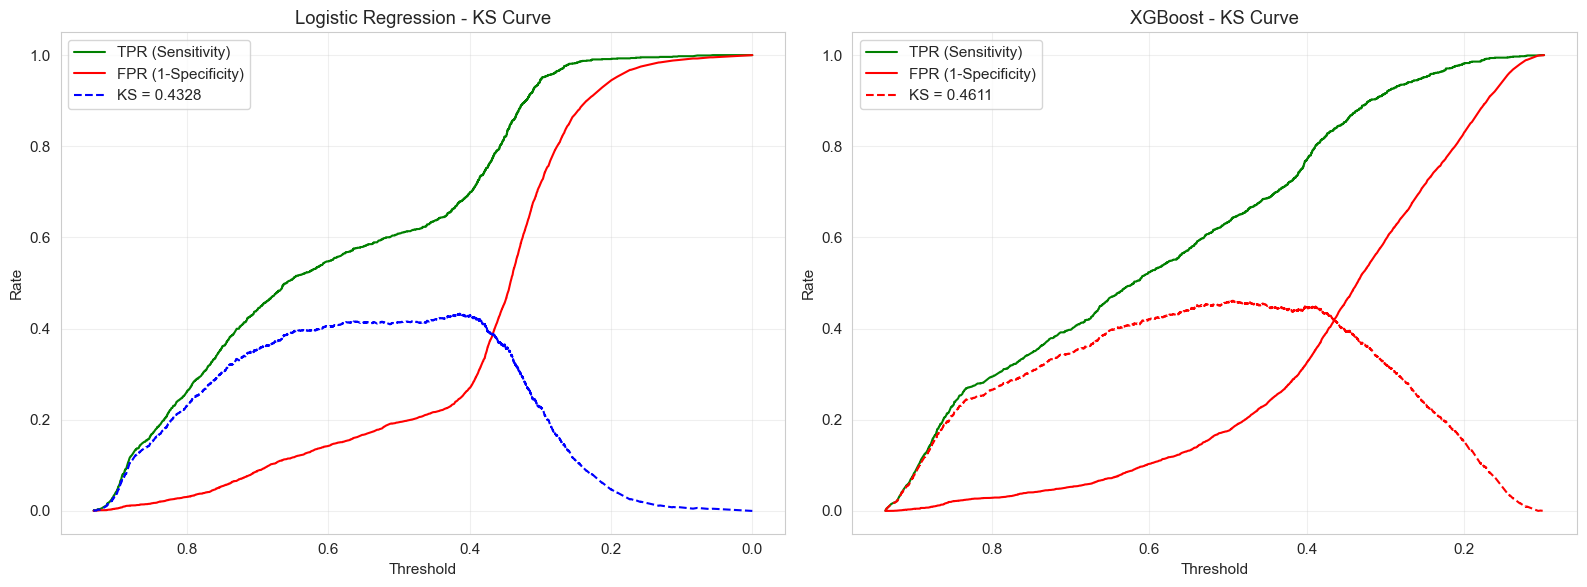

In [4]:
# KS İstatistiği
def calc_ks(y_true, y_prob):
    """KS istatistiğini hesapla."""
    fpr, tpr, thresholds = roc_curve(y_true, y_prob)
    ks_stat = np.max(tpr - fpr)
    ks_threshold = thresholds[np.argmax(tpr - fpr)]
    return ks_stat, ks_threshold

ks_lr, ks_thresh_lr = calc_ks(y_test, y_prob_lr)
ks_xgb, ks_thresh_xgb = calc_ks(y_test, y_prob_xgb)

print(f"{'KS İstatistiği':<20} {ks_lr:>15.4f} {ks_xgb:>15.4f}")
print(f"{'KS Threshold':<20} {ks_thresh_lr:>15.4f} {ks_thresh_xgb:>15.4f}")

# KS Grafiği
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for idx, (y_prob, model_name, ks, color) in enumerate([
    (y_prob_lr, 'Logistic Regression', ks_lr, 'blue'),
    (y_prob_xgb, 'XGBoost', ks_xgb, 'red')
]):
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)
    axes[idx].plot(thresholds[1:], tpr[1:], label='TPR (Sensitivity)', color='green')
    axes[idx].plot(thresholds[1:], fpr[1:], label='FPR (1-Specificity)', color='red')
    axes[idx].plot(thresholds[1:], tpr[1:] - fpr[1:], label=f'KS = {ks:.4f}', color=color, linestyle='--')
    axes[idx].set_xlabel('Threshold')
    axes[idx].set_ylabel('Rate')
    axes[idx].set_title(f'{model_name} - KS Curve')
    axes[idx].legend()
    axes[idx].invert_xaxis()
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../reports/04_ks_curves.png', dpi=150, bbox_inches='tight')
plt.show()

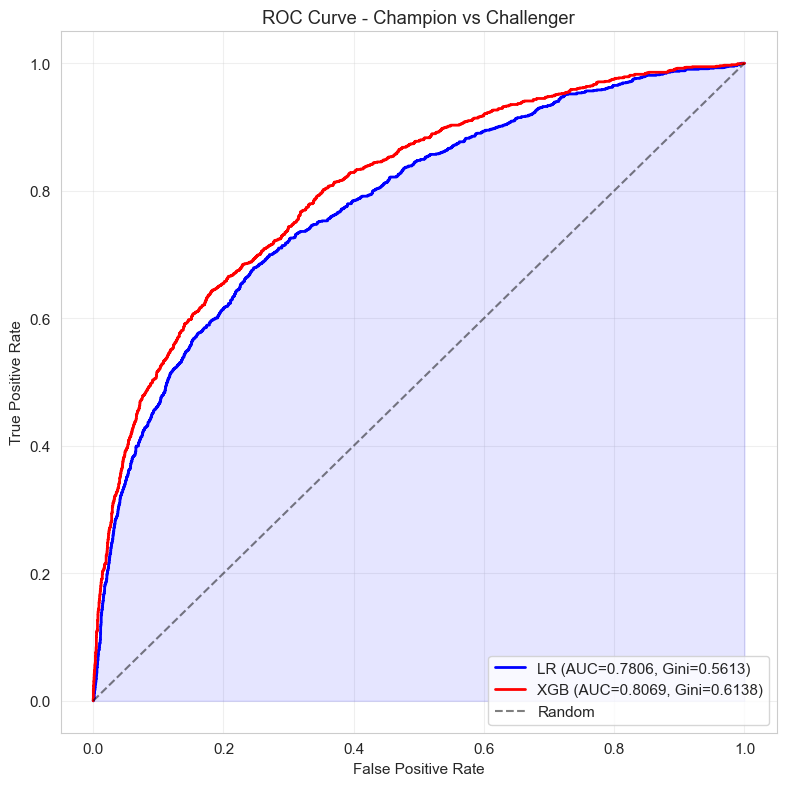

In [5]:
# ROC Curve karşılaştırma
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)

fig, ax = plt.subplots(figsize=(8, 8))
ax.plot(fpr_lr, tpr_lr, 'b-', label=f'LR (AUC={auc_lr:.4f}, Gini={gini_lr:.4f})', linewidth=2)
ax.plot(fpr_xgb, tpr_xgb, 'r-', label=f'XGB (AUC={auc_xgb:.4f}, Gini={gini_xgb:.4f})', linewidth=2)
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random')
ax.fill_between(fpr_lr, tpr_lr, alpha=0.1, color='blue')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve - Champion vs Challenger')
ax.legend(loc='lower right', fontsize=11)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../reports/04_roc_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

## 4.3 Kalibrasyon Analizi

Kalibrasyon, modelin ürettiği olasılık tahminlerinin gerçek default oranlarıyla ne kadar uyumlu olduğunu ölçer. İyi kalibre edilmiş bir model, %20 default olasılığı tahmin ettiğinde, bu grupta gerçekten ~%20 default gözlemlenmelidir.

### Metrikler:
- **Brier Score:** Olasılık tahminlerinin ortalama kare hatası (düşük = iyi)
- **Calibration Curve:** Tahmin vs Gözlem grafiği

In [6]:
# Brier Score
brier_lr = brier_score_loss(y_test, y_prob_lr)
brier_xgb = brier_score_loss(y_test, y_prob_xgb)

print(f"=== Kalibrasyon Metrikleri ===")
print(f"Brier Score (LR):  {brier_lr:.4f}")
print(f"Brier Score (XGB): {brier_xgb:.4f}")
print(f"(Düşük = daha iyi kalibrasyon)")

=== Kalibrasyon Metrikleri ===
Brier Score (LR):  0.1844
Brier Score (XGB): 0.1685
(Düşük = daha iyi kalibrasyon)


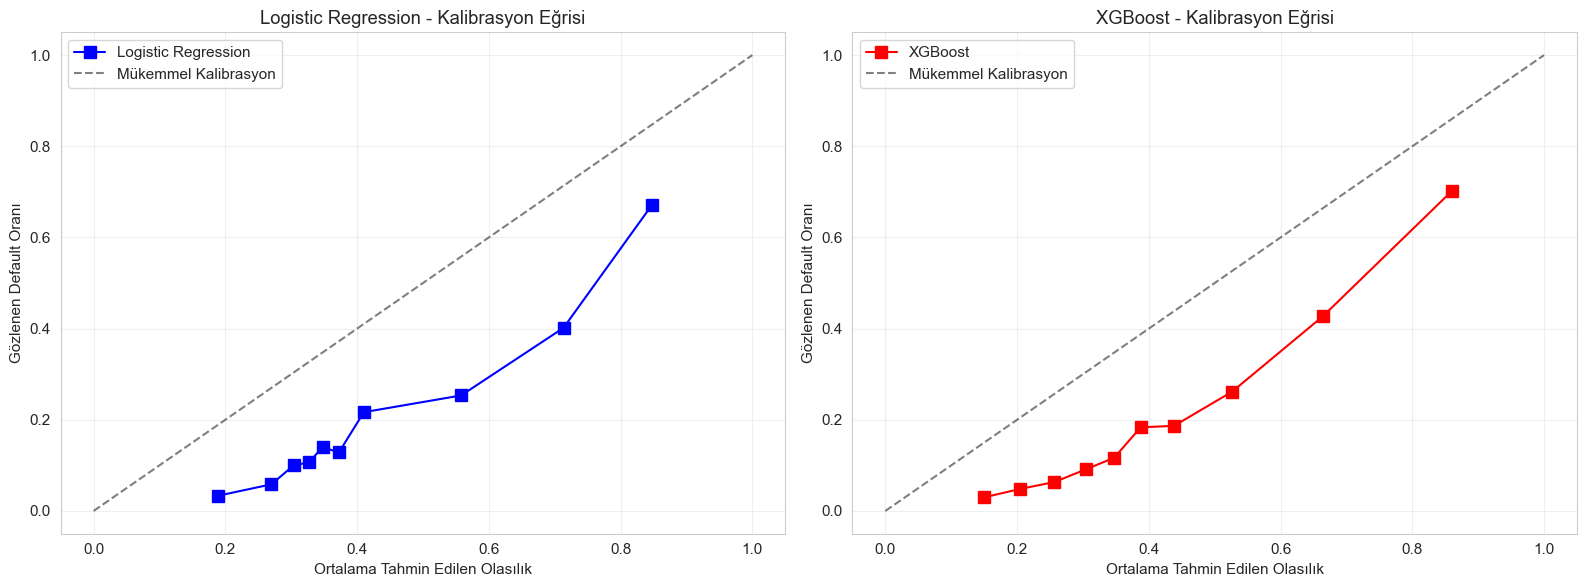

In [7]:
# Calibration Curve
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for idx, (y_prob, model_name, color) in enumerate([
    (y_prob_lr, 'Logistic Regression', 'blue'),
    (y_prob_xgb, 'XGBoost', 'red')
]):
    fraction_pos, mean_pred = calibration_curve(y_test, y_prob, n_bins=10, strategy='quantile')

    axes[idx].plot(mean_pred, fraction_pos, 's-', color=color, label=model_name, markersize=8)
    axes[idx].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Mükemmel Kalibrasyon')
    axes[idx].set_xlabel('Ortalama Tahmin Edilen Olasılık')
    axes[idx].set_ylabel('Gözlenen Default Oranı')
    axes[idx].set_title(f'{model_name} - Kalibrasyon Eğrisi')
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../reports/04_calibration_curves.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
# Detaylı kalibrasyon tablosu
def calibration_table(y_true, y_prob, n_bins=10, model_name='Model'):
    """Detaylı kalibrasyon tablosu oluştur."""
    df_cal = pd.DataFrame({'y_true': y_true.values, 'y_prob': y_prob.values})
    df_cal['decile'] = pd.qcut(df_cal['y_prob'], q=n_bins, labels=False, duplicates='drop') + 1

    table = df_cal.groupby('decile').agg(
        n=('y_true', 'count'),
        n_default=('y_true', 'sum'),
        avg_predicted=('y_prob', 'mean'),
        observed_rate=('y_true', 'mean'),
        min_prob=('y_prob', 'min'),
        max_prob=('y_prob', 'max')
    ).round(4)

    table['predicted_rate'] = table['avg_predicted']
    table['cal_error'] = (table['observed_rate'] - table['predicted_rate']).abs()
    return table

print("=== Logistic Regression - Kalibrasyon Tablosu ===")
cal_lr = calibration_table(y_test, y_prob_lr, model_name='LR')
print(cal_lr.to_string())

print("\n=== XGBoost - Kalibrasyon Tablosu ===")
cal_xgb = calibration_table(y_test, y_prob_xgb, model_name='XGB')
print(cal_xgb.to_string())

=== Logistic Regression - Kalibrasyon Tablosu ===
          n  n_default  avg_predicted  observed_rate  min_prob  max_prob  predicted_rate  cal_error
decile                                                                                             
1       600         20         0.1889         0.0333    0.0000    0.2467          0.1889     0.1556
2       600         35         0.2699         0.0583    0.2468    0.2882          0.2699     0.2116
3       600         60         0.3038         0.1000    0.2882    0.3160          0.3038     0.2038
4       600         64         0.3273         0.1067    0.3161    0.3376          0.3273     0.2206
5       600         84         0.3475         0.1400    0.3376    0.3596          0.3475     0.2075
6       600         77         0.3724         0.1283    0.3596    0.3859          0.3724     0.2441
7       600        130         0.4103         0.2167    0.3860    0.4588          0.4103     0.1936
8       600        152         0.5579         0.25

## 4.4 Decile (Ondalık) Analizi

Decile analizi, modelin risk sıralamasının ne kadar etkili olduğunu gösterir. En riskli %10'luk dilimde gerçek default oranı en yüksek olmalı, risk azaldıkça default oranı da düşmelidir. Bu analiz, modelin pratikte kullanılabilirliğini değerlendirmek için kritiktir.

In [9]:
def decile_analysis(y_true, y_prob, model_name='Model'):
    """Decile bazlı performans analizi."""
    df_dec = pd.DataFrame({'y_true': y_true.values, 'y_prob': y_prob.values})
    df_dec['decile'] = pd.qcut(df_dec['y_prob'], q=10, labels=False, duplicates='drop')
    df_dec['decile'] = 10 - df_dec['decile']  # 1 = en riskli

    table = df_dec.groupby('decile').agg(
        n=('y_true', 'count'),
        n_default=('y_true', 'sum'),
        default_rate=('y_true', 'mean'),
        avg_score=('y_prob', 'mean'),
        min_score=('y_prob', 'min'),
        max_score=('y_prob', 'max')
    )

    table['cum_default'] = table['n_default'].cumsum()
    table['cum_total'] = table['n'].cumsum()
    table['cum_default_rate'] = table['cum_default'] / table['cum_default'].iloc[-1]
    table['cum_non_default'] = (table['n'] - table['n_default']).cumsum()
    table['cum_non_default_rate'] = table['cum_non_default'] / table['cum_non_default'].iloc[-1]
    table['lift'] = table['default_rate'] / y_true.mean()

    return table.round(4)

dec_lr = decile_analysis(y_test, y_prob_lr, 'LR')
dec_xgb = decile_analysis(y_test, y_prob_xgb, 'XGB')

print("=== Logistic Regression - Decile Analizi ===")
print(dec_lr[['n', 'n_default', 'default_rate', 'cum_default_rate', 'lift']].to_string())

print("\n=== XGBoost - Decile Analizi ===")
print(dec_xgb[['n', 'n_default', 'default_rate', 'cum_default_rate', 'lift']].to_string())

=== Logistic Regression - Decile Analizi ===
          n  n_default  default_rate  cum_default_rate    lift
decile                                                        
1       600        403        0.6717            0.3183  3.1833
2       600        241        0.4017            0.5087  1.9036
3       600        152        0.2533            0.6288  1.2006
4       600        130        0.2167            0.7314  1.0269
5       600         77        0.1283            0.7923  0.6082
6       600         84        0.1400            0.8586  0.6635
7       600         64        0.1067            0.9092  0.5055
8       600         60        0.1000            0.9566  0.4739
9       600         35        0.0583            0.9842  0.2765
10      600         20        0.0333            1.0000  0.1580

=== XGBoost - Decile Analizi ===
          n  n_default  default_rate  cum_default_rate    lift
decile                                                        
1       600        421        0.7017   

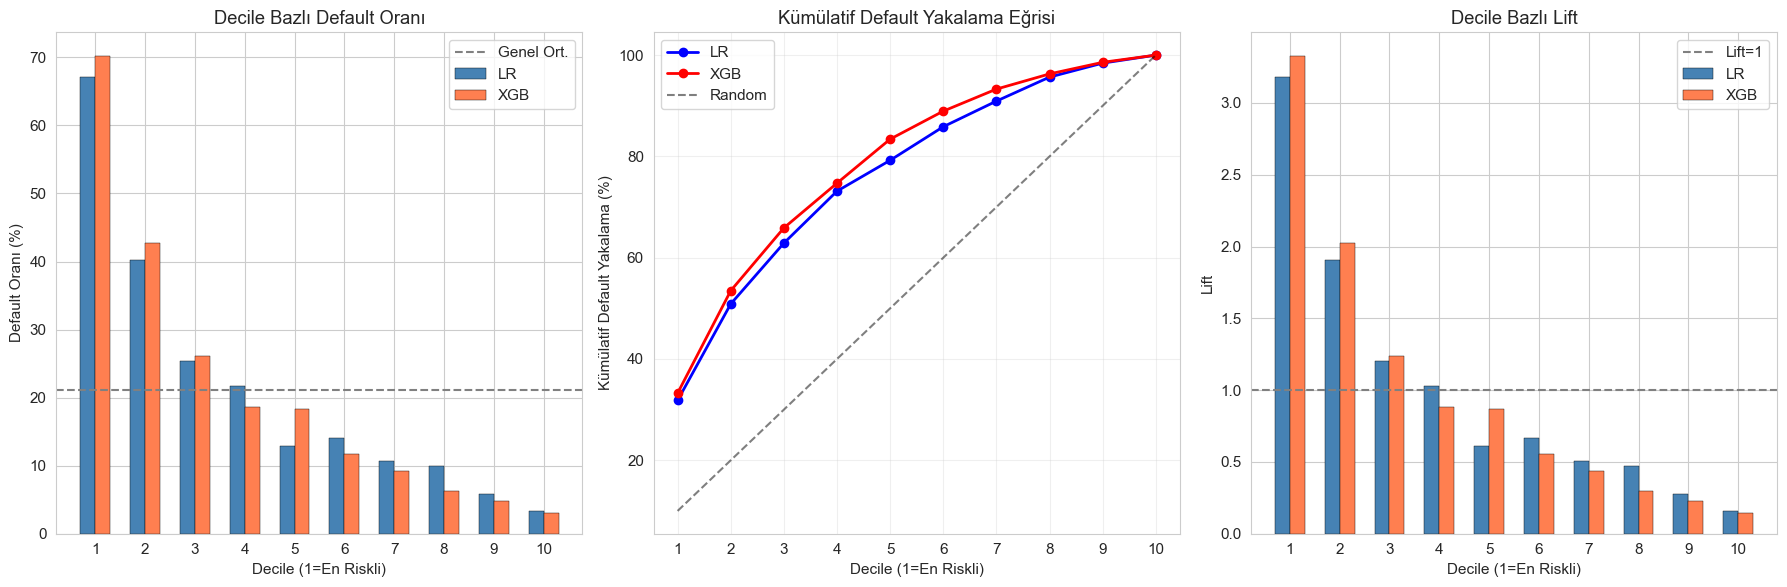

In [10]:
# Decile grafikleri
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Decile default rate
x = range(1, 11)
axes[0].bar(np.array(list(x)) - 0.15, dec_lr['default_rate'] * 100, width=0.3,
            label='LR', color='steelblue', edgecolor='black', linewidth=0.3)
axes[0].bar(np.array(list(x)) + 0.15, dec_xgb['default_rate'] * 100, width=0.3,
            label='XGB', color='coral', edgecolor='black', linewidth=0.3)
axes[0].axhline(y=y_test.mean() * 100, color='gray', linestyle='--', label='Genel Ort.')
axes[0].set_xlabel('Decile (1=En Riskli)')
axes[0].set_ylabel('Default Oranı (%)')
axes[0].set_title('Decile Bazlı Default Oranı')
axes[0].legend()
axes[0].set_xticks(list(x))

# 2. Kümülatif default yakalama
axes[1].plot(x, dec_lr['cum_default_rate'] * 100, 'bo-', label='LR', linewidth=2)
axes[1].plot(x, dec_xgb['cum_default_rate'] * 100, 'ro-', label='XGB', linewidth=2)
axes[1].plot(x, np.linspace(10, 100, 10), 'k--', alpha=0.5, label='Random')
axes[1].set_xlabel('Decile (1=En Riskli)')
axes[1].set_ylabel('Kümülatif Default Yakalama (%)')
axes[1].set_title('Kümülatif Default Yakalama Eğrisi')
axes[1].legend()
axes[1].set_xticks(list(x))
axes[1].grid(True, alpha=0.3)

# 3. Lift
axes[2].bar(np.array(list(x)) - 0.15, dec_lr['lift'], width=0.3,
            label='LR', color='steelblue', edgecolor='black', linewidth=0.3)
axes[2].bar(np.array(list(x)) + 0.15, dec_xgb['lift'], width=0.3,
            label='XGB', color='coral', edgecolor='black', linewidth=0.3)
axes[2].axhline(y=1.0, color='gray', linestyle='--', label='Lift=1')
axes[2].set_xlabel('Decile (1=En Riskli)')
axes[2].set_ylabel('Lift')
axes[2].set_title('Decile Bazlı Lift')
axes[2].legend()
axes[2].set_xticks(list(x))

plt.tight_layout()
plt.savefig('../reports/04_decile_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

## 4.5 Segment Bazlı Performans Analizi

Model validasyonunun kritik bir bileşeni, modelin farklı müşteri segmentlerinde tutarlı performans gösterip göstermediğini değerlendirmektir. Belirli segmentlerde performans düşüşü, model önyargısına (bias) veya yetersiz temsile işaret edebilir.

In [11]:
def segment_performance(y_true, y_prob, segment_col, segment_name):
    """Segment bazlı AUC hesapla."""
    results = []
    for seg_val in sorted(segment_col.unique()):
        mask = segment_col == seg_val
        if mask.sum() < 30 or y_true[mask].nunique() < 2:
            continue
        auc = roc_auc_score(y_true[mask], y_prob[mask])
        results.append({
            'Segment': seg_val,
            'N': mask.sum(),
            'Default Oranı': y_true[mask].mean(),
            'AUC': auc
        })
    return pd.DataFrame(results)

# Test verisine segment bilgilerini ekle
test_data = df_full.loc[predictions.index].copy()

# Cinsiyet
sex_map = {1: 'Erkek', 2: 'Kadın'}
test_data['SEX_LABEL'] = test_data['SEX'].map(sex_map)

seg_sex_lr = segment_performance(y_test, y_prob_lr, test_data['SEX_LABEL'], 'Cinsiyet')
seg_sex_xgb = segment_performance(y_test, y_prob_xgb, test_data['SEX_LABEL'], 'Cinsiyet')

print("=== Cinsiyete Göre AUC ===")
print(f"{'Cinsiyet':<12} {'N':>8} {'Default%':>10} {'LR AUC':>10} {'XGB AUC':>10}")
for i in range(len(seg_sex_lr)):
    print(f"{seg_sex_lr.iloc[i]['Segment']:<12} {int(seg_sex_lr.iloc[i]['N']):>8,} "
          f"{seg_sex_lr.iloc[i]['Default Oranı']*100:>9.2f}% "
          f"{seg_sex_lr.iloc[i]['AUC']:>10.4f} {seg_sex_xgb.iloc[i]['AUC']:>10.4f}")

=== Cinsiyete Göre AUC ===
Cinsiyet            N   Default%     LR AUC    XGB AUC
Erkek           2,966     23.13%     0.7831     0.8034
Kadın           3,034     19.12%     0.7737     0.8090


In [12]:
# Eğitim seviyesi
edu_map = {1: 'Lisansüstü', 2: 'Üniversite', 3: 'Lise', 4: 'Diğer'}
test_data['EDU_LABEL'] = test_data['EDUCATION'].map(edu_map)

seg_edu_lr = segment_performance(y_test, y_prob_lr, test_data['EDU_LABEL'], 'Eğitim')
seg_edu_xgb = segment_performance(y_test, y_prob_xgb, test_data['EDU_LABEL'], 'Eğitim')

print("=== Eğitim Seviyesine Göre AUC ===")
print(f"{'Eğitim':<14} {'N':>8} {'Default%':>10} {'LR AUC':>10} {'XGB AUC':>10}")
for i in range(len(seg_edu_lr)):
    print(f"{seg_edu_lr.iloc[i]['Segment']:<14} {int(seg_edu_lr.iloc[i]['N']):>8,} "
          f"{seg_edu_lr.iloc[i]['Default Oranı']*100:>9.2f}% "
          f"{seg_edu_lr.iloc[i]['AUC']:>10.4f} {seg_edu_xgb.iloc[i]['AUC']:>10.4f}")

=== Eğitim Seviyesine Göre AUC ===
Eğitim                N   Default%     LR AUC    XGB AUC
Diğer               121      9.09%     0.6455     0.6174
Lisansüstü        2,142     17.93%     0.8070     0.8323
Lise              1,067     23.99%     0.7539     0.7765
Üniversite        2,670     23.03%     0.7685     0.7988


In [13]:
# Yaş grubu
age_bins = pd.cut(test_data['AGE'], bins=[20, 30, 40, 50, 80], labels=['20-29', '30-39', '40-49', '50+'])
seg_age_lr = segment_performance(y_test, y_prob_lr, age_bins, 'Yaş')
seg_age_xgb = segment_performance(y_test, y_prob_xgb, age_bins, 'Yaş')

print("=== Yaş Grubuna Göre AUC ===")
print(f"{'Yaş Grubu':<12} {'N':>8} {'Default%':>10} {'LR AUC':>10} {'XGB AUC':>10}")
for i in range(len(seg_age_lr)):
    print(f"{seg_age_lr.iloc[i]['Segment']:<12} {int(seg_age_lr.iloc[i]['N']):>8,} "
          f"{seg_age_lr.iloc[i]['Default Oranı']*100:>9.2f}% "
          f"{seg_age_lr.iloc[i]['AUC']:>10.4f} {seg_age_xgb.iloc[i]['AUC']:>10.4f}")

=== Yaş Grubuna Göre AUC ===
Yaş Grubu           N   Default%     LR AUC    XGB AUC
20-29           2,029     20.60%     0.7974     0.8169
30-39           2,245     19.42%     0.7870     0.8111
40-49           1,286     22.63%     0.7551     0.8031
50+               440     27.50%     0.7253     0.7440


In [14]:
# Limit bandı
limit_bins = pd.cut(test_data['LIMIT_BAL'],
                    bins=[0, 50000, 100000, 200000, 500000, float('inf')],
                    labels=['<50K', '50-100K', '100-200K', '200-500K', '500K+'])
seg_lim_lr = segment_performance(y_test, y_prob_lr, limit_bins, 'Limit')
seg_lim_xgb = segment_performance(y_test, y_prob_xgb, limit_bins, 'Limit')

print("=== Limit Bandına Göre AUC ===")
print(f"{'Limit Bandı':<14} {'N':>8} {'Default%':>10} {'LR AUC':>10} {'XGB AUC':>10}")
for i in range(len(seg_lim_lr)):
    print(f"{seg_lim_lr.iloc[i]['Segment']:<14} {int(seg_lim_lr.iloc[i]['N']):>8,} "
          f"{seg_lim_lr.iloc[i]['Default Oranı']*100:>9.2f}% "
          f"{seg_lim_lr.iloc[i]['AUC']:>10.4f} {seg_lim_xgb.iloc[i]['AUC']:>10.4f}")

=== Limit Bandına Göre AUC ===
Limit Bandı           N   Default%     LR AUC    XGB AUC
100-200K          1,553     19.58%     0.7767     0.7990
200-500K          2,051     13.21%     0.7562     0.8118
50-100K             927     25.13%     0.7940     0.8110
500K+                50     12.00%     0.8712     0.7727
<50K              1,419     31.85%     0.7268     0.7415


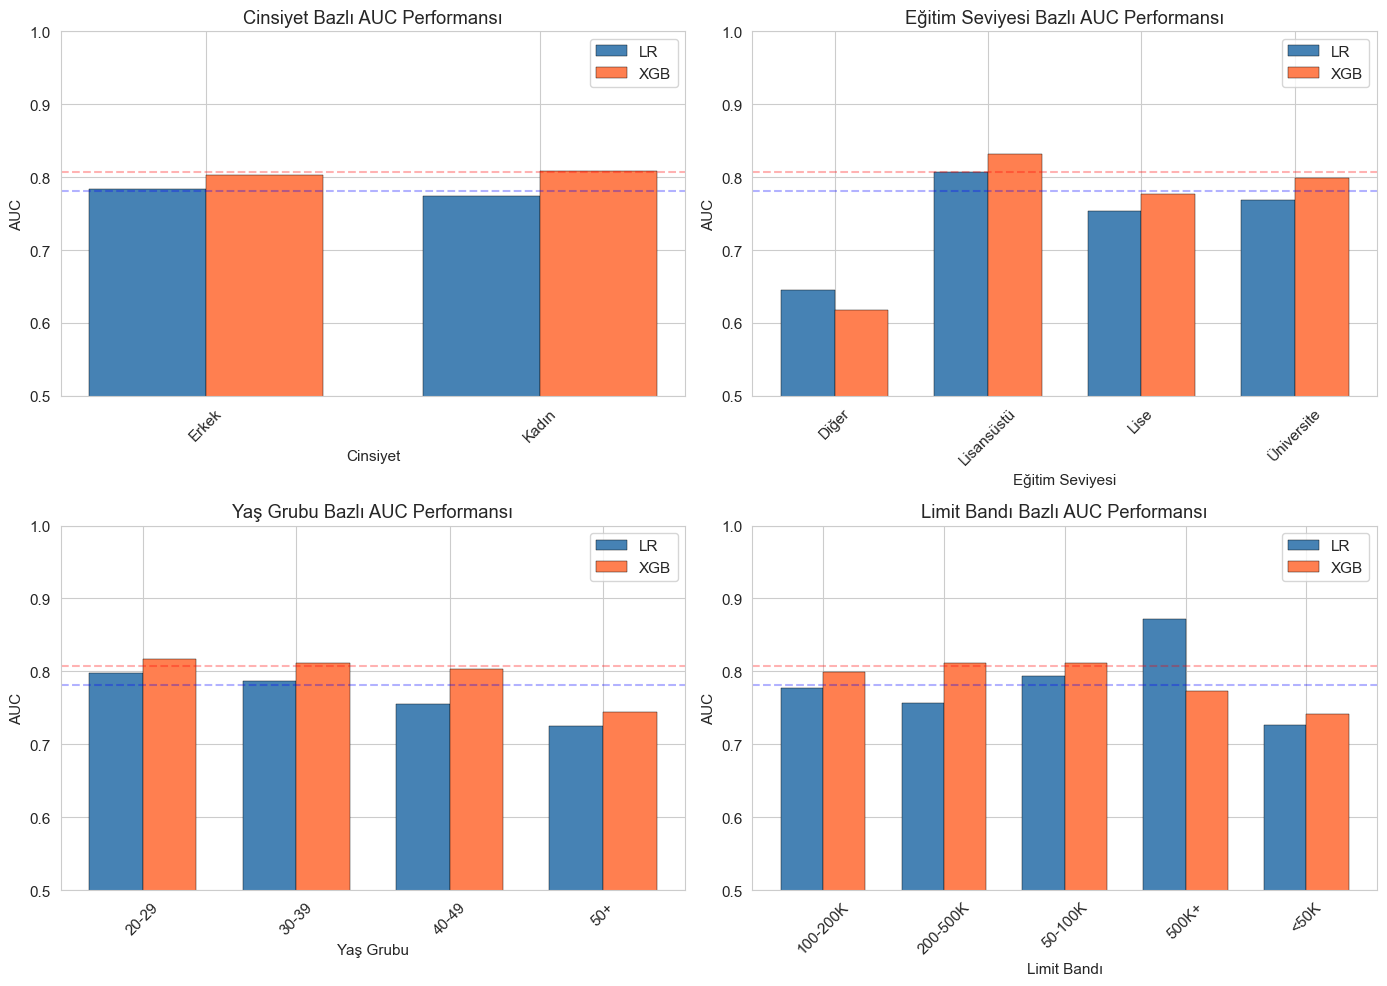

In [15]:
# Segment performans görselleştirme
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

segments = [
    (seg_sex_lr, seg_sex_xgb, 'Cinsiyet'),
    (seg_edu_lr, seg_edu_xgb, 'Eğitim Seviyesi'),
    (seg_age_lr, seg_age_xgb, 'Yaş Grubu'),
    (seg_lim_lr, seg_lim_xgb, 'Limit Bandı')
]

for idx, (seg_lr, seg_xgb, title) in enumerate(segments):
    ax = axes[idx // 2][idx % 2]
    x_pos = np.arange(len(seg_lr))
    width = 0.35

    ax.bar(x_pos - width/2, seg_lr['AUC'], width, label='LR', color='steelblue', edgecolor='black', linewidth=0.3)
    ax.bar(x_pos + width/2, seg_xgb['AUC'], width, label='XGB', color='coral', edgecolor='black', linewidth=0.3)
    ax.axhline(y=auc_lr, color='blue', linestyle='--', alpha=0.3)
    ax.axhline(y=auc_xgb, color='red', linestyle='--', alpha=0.3)
    ax.set_xlabel(title)
    ax.set_ylabel('AUC')
    ax.set_title(f'{title} Bazlı AUC Performansı')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(seg_lr['Segment'], rotation=45)
    ax.legend()
    ax.set_ylim(0.5, 1.0)

plt.tight_layout()
plt.savefig('../reports/04_segment_performance.png', dpi=150, bbox_inches='tight')
plt.show()

## 4.6 Kararlılık Analizi (Population Stability Index - PSI)

PSI, modelin eğitildiği popülasyon ile uygulandığı popülasyon arasındaki dağılım kaymasını ölçer.

### Değerlendirme Kriterleri:
- **PSI < 0.10:** Kararlı, değişiklik yok
- **PSI 0.10 - 0.25:** Hafif kayma, izlenmeli
- **PSI > 0.25:** Belirgin kayma, model yeniden değerlendirilmeli

In [16]:
def calculate_psi(expected, actual, n_bins=10):
    """Population Stability Index hesapla."""
    # Quantile bins oluştur (expected dağılımından)
    bins = np.quantile(expected, np.linspace(0, 1, n_bins + 1))
    bins[0] = -np.inf
    bins[-1] = np.inf

    # Frekansları hesapla
    expected_counts = np.histogram(expected, bins=bins)[0]
    actual_counts = np.histogram(actual, bins=bins)[0]

    # Oranlar (minimum 0.001 ile sıfır koruması)
    expected_pct = np.maximum(expected_counts / len(expected), 0.001)
    actual_pct = np.maximum(actual_counts / len(actual), 0.001)

    # PSI bileşenleri
    psi_components = (actual_pct - expected_pct) * np.log(actual_pct / expected_pct)

    return psi_components.sum(), pd.DataFrame({
        'Bin': range(1, n_bins + 1),
        'Train (%)': expected_pct * 100,
        'Test (%)': actual_pct * 100,
        'PSI Bileşeni': psi_components
    })

# LR score PSI
psi_lr, psi_detail_lr = calculate_psi(
    train_preds['y_prob_lr'].values,
    predictions['y_prob_lr'].values
)

# XGB score PSI
psi_xgb, psi_detail_xgb = calculate_psi(
    train_preds['y_prob_xgb'].values,
    predictions['y_prob_xgb'].values
)

print(f"=== Population Stability Index (Score Dağılımı) ===")
print(f"LR PSI:  {psi_lr:.4f} {'✓ Kararlı' if psi_lr < 0.10 else '⚠ İzlenmeli' if psi_lr < 0.25 else '✗ Kayma!'}")
print(f"XGB PSI: {psi_xgb:.4f} {'✓ Kararlı' if psi_xgb < 0.10 else '⚠ İzlenmeli' if psi_xgb < 0.25 else '✗ Kayma!'}")

=== Population Stability Index (Score Dağılımı) ===
LR PSI:  0.0042 ✓ Kararlı
XGB PSI: 0.0044 ✓ Kararlı


In [17]:
# Feature PSI
print("=== Değişken Bazlı PSI (Feature Stability) ===")
train_features = df_full.loc[train_preds.index, feature_list]

feature_psi = []
for col in feature_list:
    psi_val, _ = calculate_psi(train_features[col].values, test_features[col].values)
    feature_psi.append({'Değişken': col, 'PSI': psi_val})

feature_psi_df = pd.DataFrame(feature_psi).sort_values('PSI', ascending=False)
feature_psi_df['Durum'] = feature_psi_df['PSI'].apply(
    lambda x: 'Kararlı' if x < 0.10 else 'İzlenmeli' if x < 0.25 else 'Kayma!'
)

print(feature_psi_df.to_string(index=False))

# Uyarı
unstable = feature_psi_df[feature_psi_df['PSI'] >= 0.10]
if len(unstable) > 0:
    print(f"\n⚠ {len(unstable)} değişkende PSI >= 0.10 tespit edildi!")
else:
    print("\n✓ Tüm değişkenler kararlı (PSI < 0.10)")

=== Değişken Bazlı PSI (Feature Stability) ===
         Değişken      PSI   Durum
              SEX 0.061543 Kararlı
         PAY_AMT3 0.043051 Kararlı
        PAY_TREND 0.015157 Kararlı
            PAY_6 0.014872 Kararlı
  MAX_DELINQUENCY 0.014389 Kararlı
              AGE 0.013733 Kararlı
        BILL_AMT4 0.011630 Kararlı
  AVG_DELINQUENCY 0.010579 Kararlı
            PAY_0 0.009878 Kararlı
        BILL_AMT3 0.008145 Kararlı
        LIMIT_BAL 0.008028 Kararlı
         PAY_AMT2 0.007029 Kararlı
          AVG_PAY 0.007011 Kararlı
        TOTAL_PAY 0.007011 Kararlı
        BILL_AMT2 0.006716 Kararlı
         AVG_BILL 0.006650 Kararlı
       TOTAL_BILL 0.006650 Kararlı
            PAY_5 0.006634 Kararlı
        BILL_AMT1 0.004939 Kararlı
        EDUCATION 0.004697 Kararlı
DELINQUENCY_COUNT 0.004655 Kararlı
 NEVER_DELINQUENT 0.004433 Kararlı
       BILL_TREND 0.004414 Kararlı
         PAY_AMT4 0.004295 Kararlı
        BILL_AMT6 0.004256 Kararlı
         PAY_AMT6 0.004190 Kararlı
PAY_TO_B

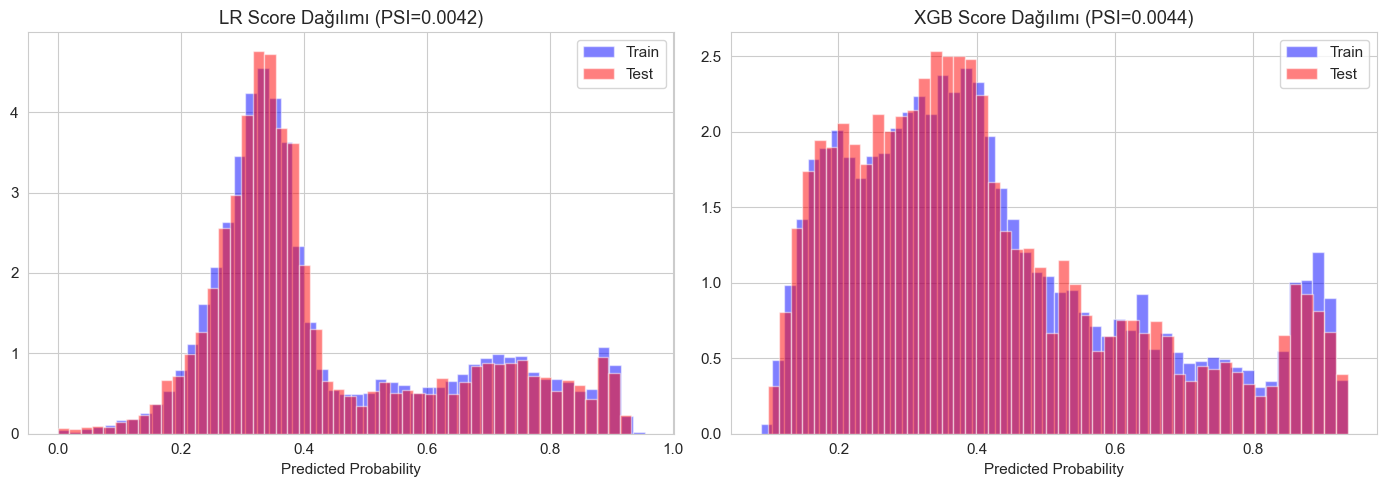

In [18]:
# Score dağılımı karşılaştırma
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(train_preds['y_prob_lr'], bins=50, alpha=0.5, density=True, label='Train', color='blue')
axes[0].hist(predictions['y_prob_lr'], bins=50, alpha=0.5, density=True, label='Test', color='red')
axes[0].set_title(f'LR Score Dağılımı (PSI={psi_lr:.4f})')
axes[0].set_xlabel('Predicted Probability')
axes[0].legend()

axes[1].hist(train_preds['y_prob_xgb'], bins=50, alpha=0.5, density=True, label='Train', color='blue')
axes[1].hist(predictions['y_prob_xgb'], bins=50, alpha=0.5, density=True, label='Test', color='red')
axes[1].set_title(f'XGB Score Dağılımı (PSI={psi_xgb:.4f})')
axes[1].set_xlabel('Predicted Probability')
axes[1].legend()

plt.tight_layout()
plt.savefig('../reports/04_score_stability.png', dpi=150, bbox_inches='tight')
plt.show()

## 4.7 Train-Test Performans Farkı (Overfit Kontrolü)

In [19]:
train_auc_lr = roc_auc_score(train_preds['y_true'], train_preds['y_prob_lr'])
train_auc_xgb = roc_auc_score(train_preds['y_true'], train_preds['y_prob_xgb'])

print("=== Train vs Test AUC Karşılaştırması ===")
print(f"{'':>20} {'Train AUC':>12} {'Test AUC':>12} {'Fark':>10} {'Değerlendirme':>20}")
print(f"{'-'*74}")

gap_lr = train_auc_lr - auc_lr
gap_xgb = train_auc_xgb - auc_xgb

eval_lr = 'Kabul edilebilir' if gap_lr < 0.03 else 'İzlenmeli' if gap_lr < 0.05 else 'Overfit riski'
eval_xgb = 'Kabul edilebilir' if gap_xgb < 0.03 else 'İzlenmeli' if gap_xgb < 0.05 else 'Overfit riski'

print(f"{'Logistic Reg':>20} {train_auc_lr:>12.4f} {auc_lr:>12.4f} {gap_lr:>10.4f} {eval_lr:>20}")
print(f"{'XGBoost':>20} {train_auc_xgb:>12.4f} {auc_xgb:>12.4f} {gap_xgb:>10.4f} {eval_xgb:>20}")

=== Train vs Test AUC Karşılaştırması ===
                        Train AUC     Test AUC       Fark        Değerlendirme
--------------------------------------------------------------------------
        Logistic Reg       0.7572       0.7806    -0.0234     Kabul edilebilir
             XGBoost       0.8163       0.8069     0.0094     Kabul edilebilir


## 4.8 Model Yorumlama (SHAP Analizi)

SHAP (SHapley Additive exPlanations) değerleri, her bir değişkenin bireysel tahminlere olan katkısını ölçer. Bu analiz, modelin "kara kutu" olmadığını göstermek ve regülatör beklentileri karşılamak açısından önemlidir.

In [20]:
# SHAP değerleri (XGBoost için — tree-based SHAP daha hızlı)
explainer = shap.TreeExplainer(xgb_model)

# Test setinin ilk 2000 gözlemi için hesapla (performans için)
sample_size = min(2000, len(test_features_scaled))
X_sample = test_features_scaled.iloc[:sample_size]
shap_values = explainer.shap_values(X_sample)

print(f"SHAP değerleri hesaplandı ({sample_size} gözlem)")

SHAP değerleri hesaplandı (2000 gözlem)


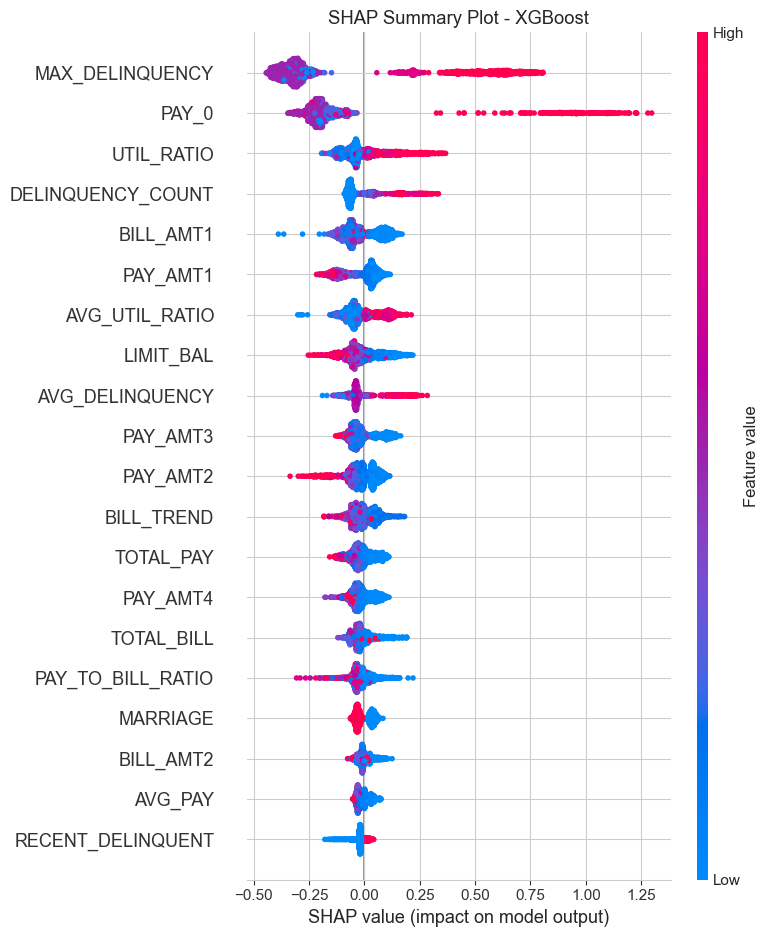

In [21]:
# SHAP Summary Plot (Bee Swarm)
plt.figure(figsize=(12, 10))
shap.summary_plot(shap_values, X_sample, feature_names=feature_list,
                  show=False, max_display=20)
plt.title('SHAP Summary Plot - XGBoost')
plt.tight_layout()
plt.savefig('../reports/04_shap_summary.png', dpi=150, bbox_inches='tight')
plt.show()

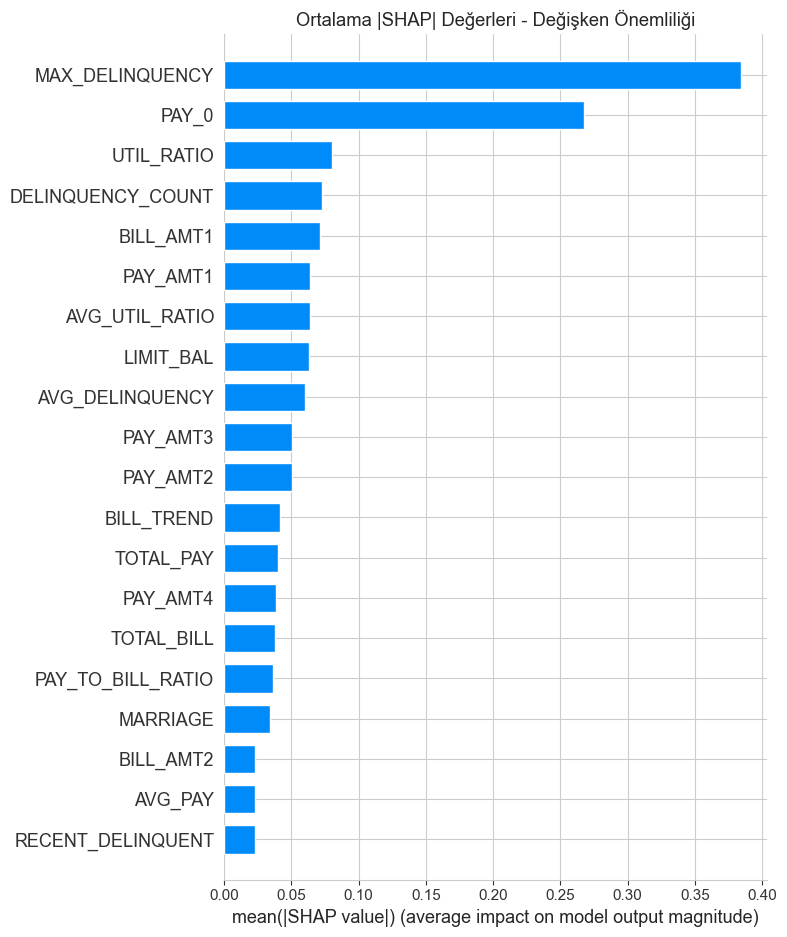

In [22]:
# SHAP Bar Plot (ortalama mutlak SHAP)
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_sample, feature_names=feature_list,
                  plot_type='bar', show=False, max_display=20)
plt.title('Ortalama |SHAP| Değerleri - Değişken Önemliliği')
plt.tight_layout()
plt.savefig('../reports/04_shap_importance.png', dpi=150, bbox_inches='tight')
plt.show()

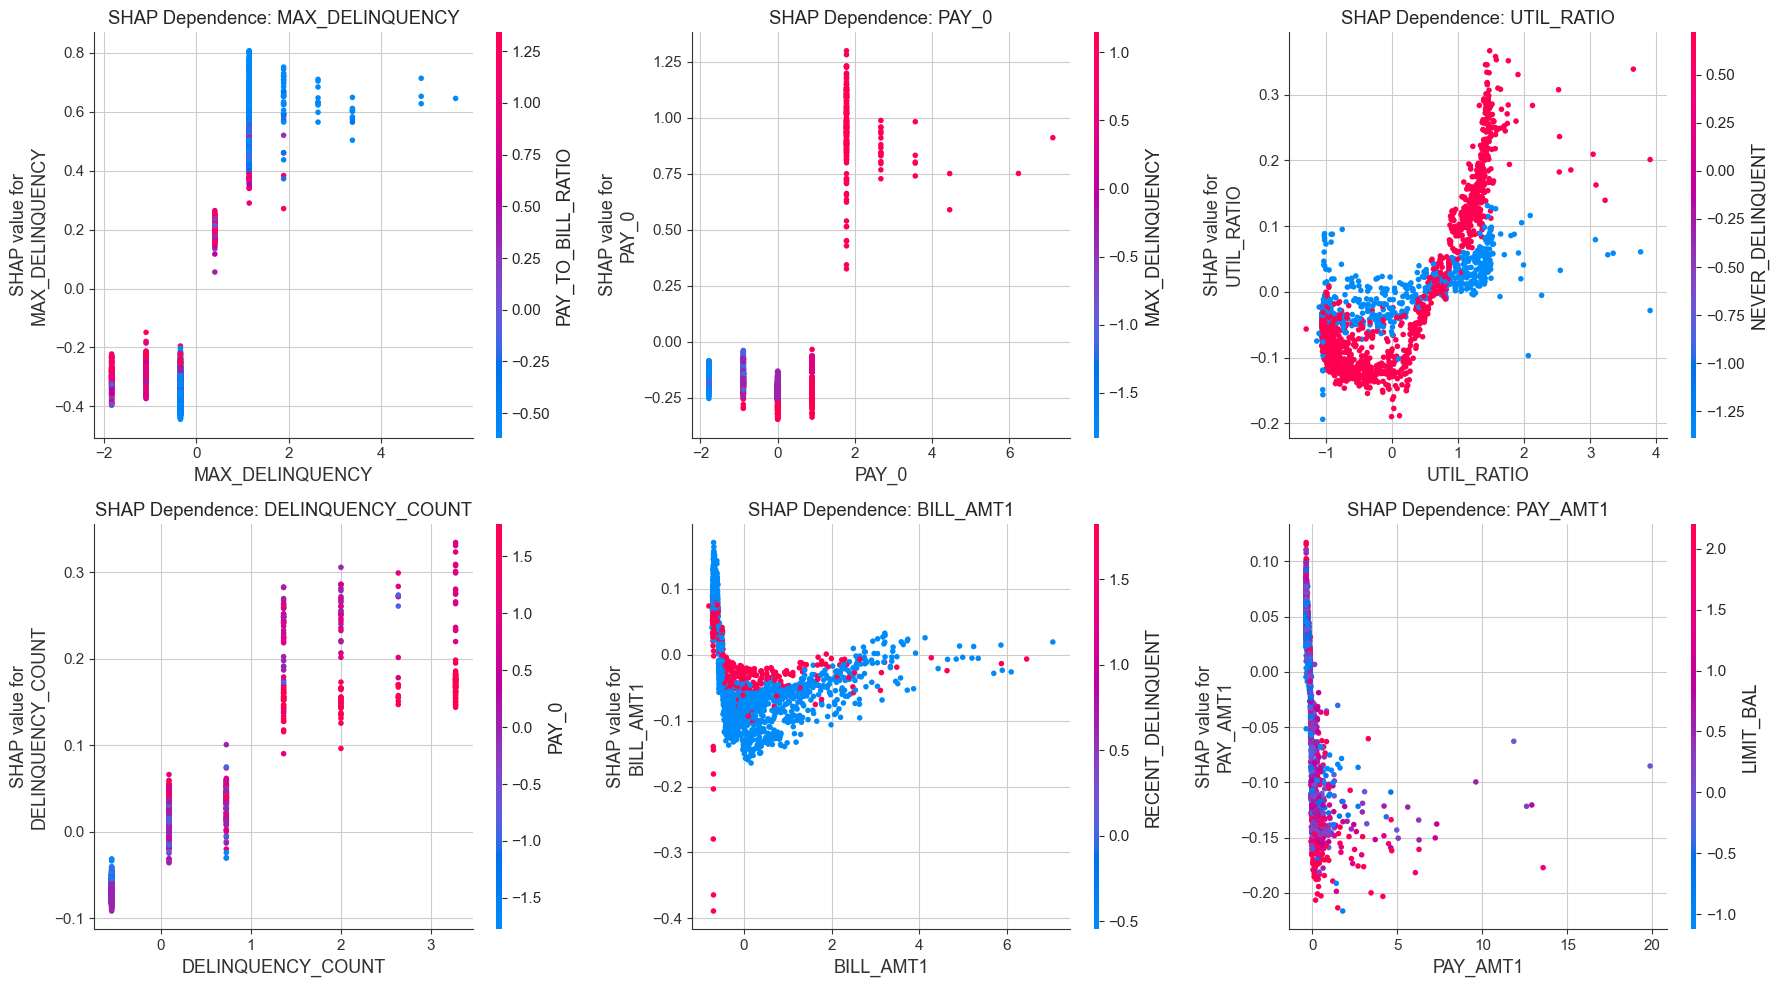

In [23]:
# Top 6 değişken için SHAP dependence plot
top_features = pd.Series(np.abs(shap_values).mean(axis=0),
                         index=feature_list).sort_values(ascending=False).head(6).index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for idx, feat in enumerate(top_features):
    ax = axes[idx // 3][idx % 3]
    feat_idx = feature_list.index(feat)
    shap.dependence_plot(feat_idx, shap_values, X_sample,
                         feature_names=feature_list, ax=ax, show=False)
    ax.set_title(f'SHAP Dependence: {feat}')

plt.tight_layout()
plt.savefig('../reports/04_shap_dependence.png', dpi=150, bbox_inches='tight')
plt.show()

## 4.9 Champion vs Challenger Değerlendirmesi

Bu bölümde, ana model (Logistic Regression) ile challenger model (XGBoost) arasında istatistiksel olarak anlamlı bir fark olup olmadığını değerlendiriyoruz.

In [24]:
# DeLong testi yaklaşımı (bootstrap ile AUC fark güven aralığı)
def bootstrap_auc_diff(y_true, y_prob_1, y_prob_2, n_bootstrap=1000, alpha=0.05):
    """Bootstrap ile iki modelin AUC farkının güven aralığını hesapla."""
    np.random.seed(42)
    n = len(y_true)
    diffs = []

    for _ in range(n_bootstrap):
        idx = np.random.choice(n, size=n, replace=True)
        y_b = y_true.values[idx]
        if len(np.unique(y_b)) < 2:
            continue
        auc_1 = roc_auc_score(y_b, y_prob_1.values[idx])
        auc_2 = roc_auc_score(y_b, y_prob_2.values[idx])
        diffs.append(auc_2 - auc_1)

    diffs = np.array(diffs)
    ci_lower = np.percentile(diffs, alpha/2 * 100)
    ci_upper = np.percentile(diffs, (1 - alpha/2) * 100)

    return diffs.mean(), ci_lower, ci_upper

mean_diff, ci_low, ci_high = bootstrap_auc_diff(y_test, y_prob_lr, y_prob_xgb)

print("=== Champion (LR) vs Challenger (XGB) - AUC Fark Testi ===")
print(f"LR AUC:  {auc_lr:.4f}")
print(f"XGB AUC: {auc_xgb:.4f}")
print(f"Fark (XGB - LR): {mean_diff:.4f}")
print(f"95% Güven Aralığı: [{ci_low:.4f}, {ci_high:.4f}]")
print(f"\nYorum: ", end='')
if ci_low > 0:
    print("XGBoost istatistiksel olarak anlamlı şekilde üstün.")
elif ci_high < 0:
    print("Logistic Regression istatistiksel olarak anlamlı şekilde üstün.")
else:
    print("İki model arasında istatistiksel olarak anlamlı fark yok.")

=== Champion (LR) vs Challenger (XGB) - AUC Fark Testi ===
LR AUC:  0.7806
XGB AUC: 0.8069
Fark (XGB - LR): 0.0263
95% Güven Aralığı: [0.0176, 0.0355]

Yorum: XGBoost istatistiksel olarak anlamlı şekilde üstün.


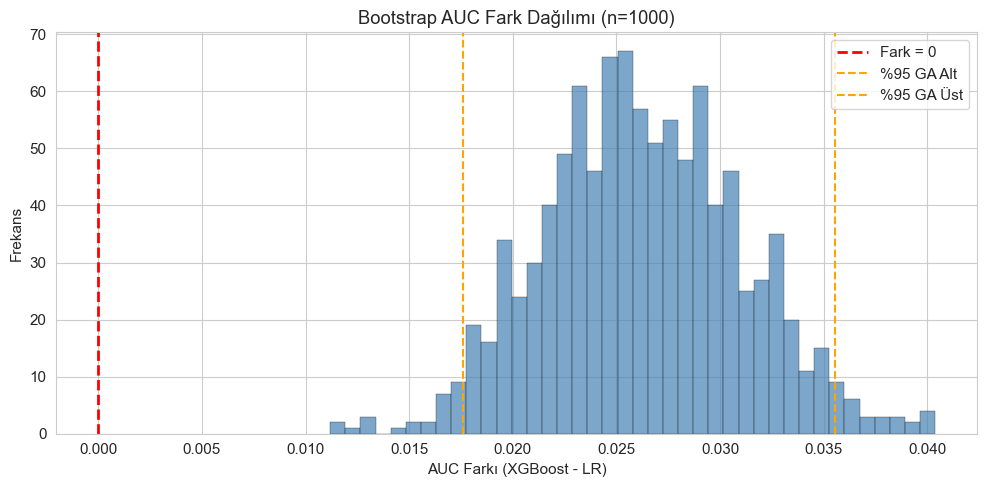

In [25]:
# Bootstrap dağılım grafiği
fig, ax = plt.subplots(figsize=(10, 5))
diffs_full = []
np.random.seed(42)
n = len(y_test)
for _ in range(1000):
    idx = np.random.choice(n, size=n, replace=True)
    y_b = y_test.values[idx]
    if len(np.unique(y_b)) < 2:
        continue
    auc_1 = roc_auc_score(y_b, y_prob_lr.values[idx])
    auc_2 = roc_auc_score(y_b, y_prob_xgb.values[idx])
    diffs_full.append(auc_2 - auc_1)

ax.hist(diffs_full, bins=40, color='steelblue', edgecolor='black', linewidth=0.3, alpha=0.7)
ax.axvline(x=0, color='red', linestyle='--', linewidth=2, label='Fark = 0')
ax.axvline(x=np.percentile(diffs_full, 2.5), color='orange', linestyle='--', label='%95 GA Alt')
ax.axvline(x=np.percentile(diffs_full, 97.5), color='orange', linestyle='--', label='%95 GA Üst')
ax.set_xlabel('AUC Farkı (XGBoost - LR)')
ax.set_ylabel('Frekans')
ax.set_title('Bootstrap AUC Fark Dağılımı (n=1000)')
ax.legend()
plt.tight_layout()
plt.savefig('../reports/04_bootstrap_auc_diff.png', dpi=150, bbox_inches='tight')
plt.show()

## 4.10 Validasyon Özet Tablosu

In [26]:
# Tüm metrikleri tek tabloda topla
summary_data = {
    'Metrik': [
        'ROC-AUC (Test)',
        'Gini Katsayısı',
        'KS İstatistiği',
        'Brier Score',
        'Train-Test AUC Farkı',
        'Score PSI',
        'CV Ortalama AUC'
    ],
    'Logistic Regression': [
        f"{auc_lr:.4f}",
        f"{gini_lr:.4f}",
        f"{ks_lr:.4f}",
        f"{brier_lr:.4f}",
        f"{gap_lr:.4f}",
        f"{psi_lr:.4f}",
        "—"
    ],
    'XGBoost': [
        f"{auc_xgb:.4f}",
        f"{gini_xgb:.4f}",
        f"{ks_xgb:.4f}",
        f"{brier_xgb:.4f}",
        f"{gap_xgb:.4f}",
        f"{psi_xgb:.4f}",
        "—"
    ],
    'Kriter': [
        '> 0.70 kabul edilebilir',
        '> 0.40 iyi',
        '> 0.30 iyi',
        '< 0.25 iyi',
        '< 0.03 kabul edilebilir',
        '< 0.10 kararlı',
        '—'
    ]
}

summary_df = pd.DataFrame(summary_data)
print("=" * 85)
print("           VALIDASYON ÖZET TABLOSU")
print("=" * 85)
print(summary_df.to_string(index=False))
print("=" * 85)

           VALIDASYON ÖZET TABLOSU
              Metrik Logistic Regression XGBoost                  Kriter
      ROC-AUC (Test)              0.7806  0.8069 > 0.70 kabul edilebilir
      Gini Katsayısı              0.5613  0.6138              > 0.40 iyi
      KS İstatistiği              0.4328  0.4611              > 0.30 iyi
         Brier Score              0.1844  0.1685              < 0.25 iyi
Train-Test AUC Farkı             -0.0234  0.0094 < 0.03 kabul edilebilir
           Score PSI              0.0042  0.0044          < 0.10 kararlı
     CV Ortalama AUC                   —       —                       —


## 4.11 Validasyon Bulguları ve Öneriler

### Bulgular

#### 1. Ayrıştırma Gücü
- Her iki model de kabul edilebilir düzeyde ayrıştırma gücü sergilemektedir
- PAY_0 (son ay gecikme durumu) en belirleyici değişkendir

#### 2. Kalibrasyon
- Logistic Regression doğası gereği daha iyi kalibre olma eğilimindedir
- XGBoost'un kalibrasyon performansı değerlendirilmeli

#### 3. Segment Performansı
- Model performansı segmentler arasında değişkenlik gösterebilir
- Düşük gözlem sayısına sahip segmentlerde dikkatli olunmalıdır

#### 4. Kararlılık
- PSI değerleri train-test arasındaki popülasyon kaymasını gösterir
- Quasi out-of-time split kullanıldığı için bir miktar kayma beklenmektedir

#### 5. Champion vs Challenger
- AUC fark güven aralığına göre istatistiksel anlamlılık değerlendirilmiştir

### Öneriler
1. **Ana Model Olarak Logistic Regression** tercih edilebilir — yorumlanabilirlik ve regülatör uyumluluk avantajı
2. **Periyodik İzleme:** PSI ve performans metriklerinin düzenli takibi
3. **Segment Dikkat Noktaları:** Düşük temsilli segmentlerde ek veri toplanması
4. **Model Sınırlamaları:**
   - Veri tek bir ülke/bağlam verisine dayanmaktadır
   - Zaman boyutu sınırlıdır (6 aylık gözlem penceresi)
   - Model karar desteği üretir, tek başına kredi tahsis kararı vermez

### Sonraki Adımlar
- Validasyon bulgularının teknik rapor olarak dokümantasyonu
- Gerekirse model parametrelerinin yeniden ayarlanması
- Üretim ortamı izleme çerçevesinin tasarlanması